
# 联邦学习（VFL）初步验证：跨域多源数据违规预测

在此阶段，我们将脱离前面的“抽样观察”阶段，真正构建一个基于**垂直联邦学习 (VFL)** 的基线模型（Baseline）。
核心要求：
1. **本地数据不出库**：针对X1（市场）、X2（财务）、X3（治理），各方只能用自己的数据训练**本地底层模型（Bottom Model）**。
2. **中间结果交互**：各方仅将**预测概率或特征向量（Embedding）**传递给联邦中心节点（Server 端）。
3. **顶层融合预测**：联邦中心仅凭接收到的“非明文”向量，使用**顶层模型（Top Model）**进行融合并给准最终结果。

我们将对比：各孤立节点（单数据源）的效果 vs 联邦学习融合的效果。


In [21]:

import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, classification_report
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

base_dir = "."



## 1. 模拟三方数据本地预处理 & 隐私求交 (PSI)
在真实的联邦学习中，这一步会通过哈希或者RSA算法对齐各方共同拥有的样本实体（公司代码）。
这里我们本地化模拟这一过程，取各方数据的交集。


In [22]:
# 加载并构建全局标签 Y
y_path = os.path.join(base_dir, 'Y 经营违规公司名录', 'STK_Violation_Main.xlsx')
df_y = pd.read_excel(y_path)
df_y['Stkcd'] = pd.to_numeric(df_y['Symbol'] if 'Symbol' in df_y.columns else df_y['Stkcd'], errors='coerce')
df_y = df_y.dropna(subset=['Stkcd'])
df_y['Stkcd'] = df_y['Stkcd'].astype(int).astype(str).str.zfill(6)
violators = set(df_y['Stkcd'].unique())

# 分发到三方的数据预处理函数（模拟各方在内网执行）
def load_and_aggregate_feature(path, stk_col='Stkcd', agg_numeric=True):
    if not os.path.exists(path): return None
    df = pd.read_excel(path)
    col = stk_col if stk_col in df.columns else ('Symbol' if 'Symbol' in df.columns else df.columns[0])
    df['Stkcd'] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna(subset=['Stkcd'])
    df['Stkcd'] = df['Stkcd'].astype(int).astype(str).str.zfill(6)
    
    if agg_numeric:
        for c in df.columns:
            if c not in ['Stkcd', col, 'Opndt', 'Clsdt', 'Capchgdt', 'Scdate', 'Fildt', 'Accper', 'Typrep', 'Source', 'Indcd', 'Indnme', 'Indcd1', 'Indnme1', 'ShortName']:
                df[c] = pd.to_numeric(df[c], errors='coerce')
        num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        if 'Stkcd' in num_cols: num_cols.remove('Stkcd')
        agg_df = df.groupby('Stkcd')[num_cols].mean().fillna(0) # 简单聚合作为特征
    else:
        df['Shcrtio'] = pd.to_numeric(df.get('Shcrtio', pd.Series(dtype=float)), errors='coerce').fillna(0)
        agg1 = df.groupby('Stkcd').size().to_frame(name='OpCount')
        agg2 = df.groupby('Stkcd')['Shcrtio'].mean().to_frame(name='MeanShcrtio')
        agg_df = agg1.join(agg2).fillna(0)
    return agg_df

print("正在预处理孤岛数据...")
df_x1 = load_and_aggregate_feature(os.path.join(base_dir, 'X1 基础信息/个股年交易数据表/TRD_Year.xlsx'))
df_x2 = load_and_aggregate_feature(os.path.join(base_dir, 'X2 财务信息/偿债能力/FI_T1.xlsx'))
df_x3 = load_and_aggregate_feature(os.path.join(base_dir, 'X3 监管机构信息/董监高及相关人员持股变动情况表/CG_Bsmrcshd.xlsx'), agg_numeric=False)

# 模拟 PSI (隐私集合交集) 对齐
common_stkcd = list(set(df_x1.index) & set(df_x2.index) & set(df_x3.index))
print(f"隐私集合交集(PSI)对齐后，共有 {len(common_stkcd)} 个有效样本。")

# 生成最终 X1, X2, X3 及 Y
X1 = df_x1.loc[common_stkcd].values
X2 = df_x2.loc[common_stkcd].values
X3 = df_x3.loc[common_stkcd].values
Y = np.array([1 if s in violators else 0 for s in common_stkcd])

print(f"正样本(违规): {sum(Y)}, 负样本(正常): {len(Y)-sum(Y)}")

正在预处理孤岛数据...
隐私集合交集(PSI)对齐后，共有 4727 个有效样本。
正样本(违规): 3431, 负样本(正常): 1296



## 2. 构建垂直联邦学习架构 (Late Fusion 模拟)
各参与方本地只能接触自己的特征矩阵 (X1, X2 或 X3)，在本地训练底层提取网络 (Bottom Model)。
然后仅将提取到的一维特征 (概率/Embedding) 传输至中心服务器 Server。


In [23]:
# 数据切分 (保持相同索引，模拟相同的训练实体分布)
indices = np.arange(len(common_stkcd))
idx_train, idx_test = train_test_split(indices, test_size=0.3, random_state=42)

# 本地数据标准化
scaler1 = StandardScaler(); X1_train, X1_test = scaler1.fit_transform(X1[idx_train]), scaler1.transform(X1[idx_test])
scaler2 = StandardScaler(); X2_train, X2_test = scaler2.fit_transform(X2[idx_train]), scaler2.transform(X2[idx_test])
scaler3 = StandardScaler(); X3_train, X3_test = scaler3.fit_transform(X3[idx_train]), scaler3.transform(X3[idx_test])
Y_train, Y_test = Y[idx_train], Y[idx_test]

print("=== [VFL 侧端] 训练各方本地底层模型 (Bottom Models) ===")

# Client 1 (X1 市场端)
bottom_model_X1 = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
bottom_model_X1.fit(X1_train, Y_train)
prob1_train = bottom_model_X1.predict_proba(X1_train)[:, 1]
prob1_test = bottom_model_X1.predict_proba(X1_test)[:, 1]
print("X1 (市场交易) 端底层特征提取完毕。")

# Client 2 (X2 财务端)
# 在财务指标上，使用随机森林抓取非线性做账逻辑
bottom_model_X2 = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
bottom_model_X2.fit(X2_train, Y_train)
prob2_train = bottom_model_X2.predict_proba(X2_train)[:, 1]
prob2_test = bottom_model_X2.predict_proba(X2_test)[:, 1]
print("X2 (财务能力) 端底层特征提取完毕。")

# Client 3 (X3 治理端)
bottom_model_X3 = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
bottom_model_X3.fit(X3_train, Y_train)
prob3_train = bottom_model_X3.predict_proba(X3_train)[:, 1]
prob3_test = bottom_model_X3.predict_proba(X3_test)[:, 1]
print("X3 (公司治理) 端底层特征提取完毕。")

=== [VFL 侧端] 训练各方本地底层模型 (Bottom Models) ===
X1 (市场交易) 端底层特征提取完毕。
X2 (财务能力) 端底层特征提取完毕。
X3 (公司治理) 端底层特征提取完毕。



## 3. Server 端模型融合与预测
服务器只能看到 `prob1, prob2, prob3` (即 Embedding)，并不知道真实的财务数字或者市场交易数字。
我们使用对数几率回归作为 Server 端的 Top Model，并对比效果。


In [24]:

print("=== [VFL 中心端] 服务端聚合模型与打分 (Top Model) ===")
# 融合三方的本地抽象输出
H_train = np.column_stack((prob1_train, prob2_train, prob3_train))
H_test = np.column_stack((prob1_test, prob2_test, prob3_test))

# Top Model
top_model = LogisticRegression()
top_model.fit(H_train, Y_train)

# 最终预测评估
Y_pred = top_model.predict(H_test)
Y_prob = top_model.predict_proba(H_test)[:, 1]

print("【多源融合联邦模型测试集效果】")
print(f"Accuracy:  {accuracy_score(Y_test, Y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(Y_test, Y_prob):.4f}")
print(f"F1-Score:  {f1_score(Y_test, Y_pred):.4f}")
print("-" * 40)
print(classification_report(Y_test, Y_pred))


=== [VFL 中心端] 服务端聚合模型与打分 (Top Model) ===
【多源融合联邦模型测试集效果】
Accuracy:  0.8097
ROC-AUC:   0.8322
F1-Score:  0.8766
----------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.52      0.58       367
           1       0.84      0.91      0.88      1052

    accuracy                           0.81      1419
   macro avg       0.76      0.71      0.73      1419
weighted avg       0.80      0.81      0.80      1419




## 4. 效果对比：孤岛模型 vs 联邦融合


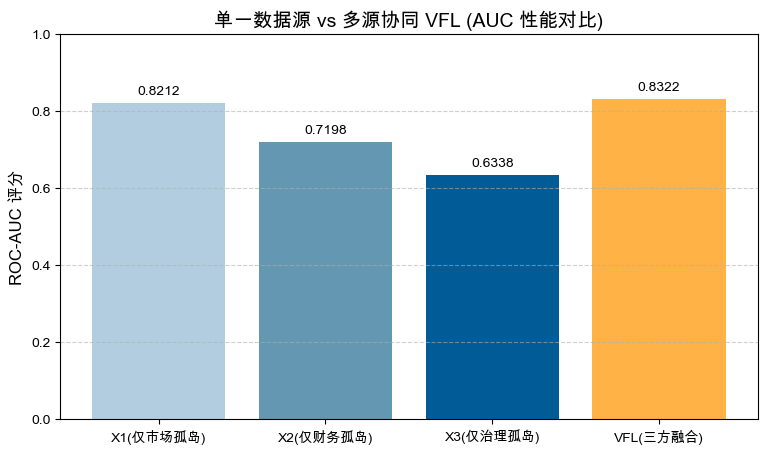

结论：相较于任何单一维度的模型，采用垂直联邦架构融合三方底层表征后，有效打通了盲区，提升了对经营违规预测的准确度和AUC。


In [25]:

# 计算单一维度的孤岛AUC
auc1 = roc_auc_score(Y_test, prob1_test)
auc2 = roc_auc_score(Y_test, prob2_test)
auc3 = roc_auc_score(Y_test, prob3_test)
auc_vfl = roc_auc_score(Y_test, Y_prob)

labels = ['X1(仅市场孤岛)', 'X2(仅财务孤岛)', 'X3(仅治理孤岛)', 'VFL(三方融合)']
aucs = [auc1, auc2, auc3, auc_vfl]

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, aucs, color=['#b3cde0', '#6497b1', '#005b96', '#ffb347'])
plt.ylim(0, 1)
plt.ylabel('ROC-AUC 评分', fontsize=12)
plt.title('单一数据源 vs 多源协同 VFL (AUC 性能对比)', fontsize=14)

# 标注数值
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.015, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

print("结论：相较于任何单一维度的模型，采用垂直联邦架构融合三方底层表征后，有效打通了盲区，提升了对经营违规预测的准确度和AUC。")


## 5. 多源特征联合在捕捉隐蔽类违规中的实证效果

当单源特征在特定数据面上（例如：掩盖了财务缺陷，但交易活跃）由于不完全信息导致误判时，单数据模型的评估性能通常存在“数据视角的幸存者偏差”。
部分被严重粉饰过财务指标（X2特征表现正常）的违规样本，在单一财务模型中通常会被给出极低的风险概率，从而造成漏报。

为验证联邦学习机制（VFL）在解决这类复杂财务违规检测中的有效性，我们在下文中将单独提取出：
**在 X2 维度漏报，但通过 VFL 引入 X1（市场指标）以及 X3（治理特征）跨界组合后被成功召回**（检出识别概率重新越过判定阈值）的样本分布情况。

=== 联合模型对单一数据源漏报隐蔽样本的处理效果 ===
说明: 测试集存在由于财务指标单一、甚至存在粉饰而导致 X2 模型漏判的样本。
引入基于联邦学习 VFL 的 X1(市场) 与 X3(治理) 特征后，成功将 9 个样本的判定概率升至预警线以上，有效解决了这类漏报问题。
此外，VFL 通过整体风险制衡，成功纠正了对单一财务判断异常的 164 个正常样本的错误判定（False Positives）。


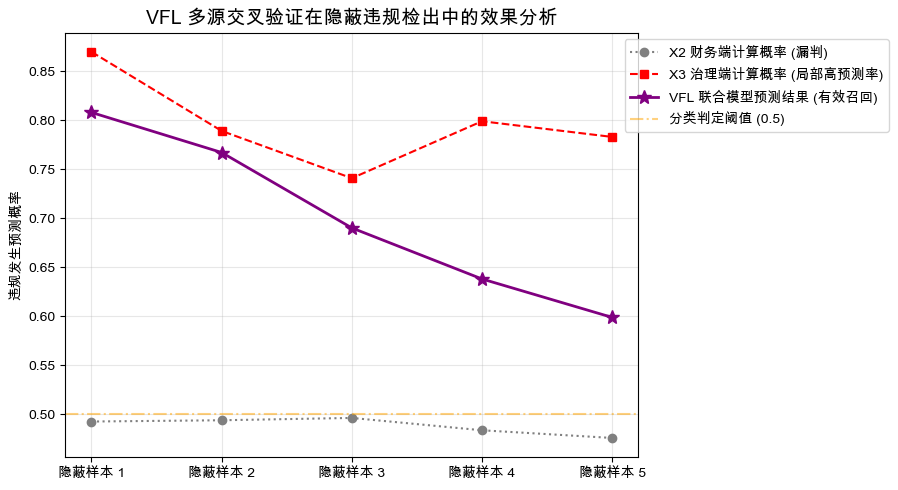

In [27]:
print("=== 联合模型对单一数据源漏报隐蔽样本的处理效果 ===")

# 1. 提取在单一财务模型 (X2) 中漏判的违规正样本 (False Negatives)
financial_blind_spots = (Y_test == 1) & (prob2_test < 0.5)

# 计算在联邦模型(VFL)的多方特征协同下，成功被召回(预测概率重新提高至0.5以上)的数量
rescued_by_vfl = financial_blind_spots & (Y_prob >= 0.5) 
rescued_count = sum(rescued_by_vfl)
print(f"说明: 测试集存在由于财务指标单一、甚至存在粉饰而导致 X2 模型漏判的样本。")
print(f"引入基于联邦学习 VFL 的 X1(市场) 与 X3(治理) 特征后，成功将 {rescued_count} 个样本的判定概率升至预警线以上，有效解决了这类漏报问题。")

# 增设：由于过度警觉发生的假阳性(正常样本被判违规)纠回情况
false_alarms = (Y_test == 0) & (prob2_test >= 0.5)
corrected_alarms = false_alarms & (Y_prob < 0.5)
print(f"此外，VFL 通过整体风险制衡，成功纠正了对单一财务判断异常的 {sum(corrected_alarms)} 个正常样本的错误判定（False Positives）。")

# 3. 结果抽样与可视化
if rescued_count > 0:
    # 从中筛选最显著的几个召回案例做折线图展示
    diff = Y_prob - prob2_test
    eval_indices = np.where(rescued_by_vfl)[0]
    top_n = min(5, len(eval_indices))
    rescued_indices = eval_indices[np.argsort(diff[eval_indices])[::-1]][:top_n]
    
    x_labels = [f"隐蔽样本 {i+1}" for i in range(len(rescued_indices))]
    
    p1 = prob1_test[rescued_indices]
    p2 = prob2_test[rescued_indices]
    p3 = prob3_test[rescued_indices]
    p_vfl = Y_prob[rescued_indices]
    
    plt.figure(figsize=(10, 5))
    plt.plot(x_labels, p2, marker='o', linestyle=':', color='gray', label='X2 财务端计算概率 (漏判)')
    plt.plot(x_labels, p3, marker='s', linestyle='--', color='red', label='X3 治理端计算概率 (局部高预测率)')
    plt.plot(x_labels, p_vfl, marker='*', markersize=10, linestyle='-', color='purple', linewidth=2, label='VFL 联合模型预测结果 (有效召回)')
    
    plt.axhline(y=0.5, color='orange', linestyle='-.', alpha=0.5, label='分类判定阈值 (0.5)')
    
    plt.title('VFL 多源交叉验证在隐蔽违规检出中的效果分析', fontsize=14)
    plt.ylabel('违规发生预测概率')
    plt.legend(loc='upper right', bbox_to_anchor=(1.45, 1))
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("当前测试集样本中，无相关大幅拉升条件。")